# Car Price Prediction with Machine Learning

## Objective
To build a machine learning model that predicts the selling price of a car using relevant features from a car price dataset.

## Project Workflow
1. Load and inspect the dataset.
2. Clean and preprocess the data.
3. Perform exploratory data analysis.
4. Select relevant features for prediction.
5. Train and evaluate machine learning models.
6. Compare model performance and identify the best model.
7. Make sample predictions and write the conclusion.

## Tools and Libraries
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Google Colab

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/sample_data/CarPrice_Assignment.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (205, 26)


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [ ]:
print("Column Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe(include="all"))

Column Names:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

Data Types:
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio           float64
stroke              float64
compressionratio    float64
horsepower            int64
peakrpm     

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205,205,205,205,205,205,205,205.000000,...,205.000000,205,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
unique,NaN,NaN,147,2,2,2,5,3,2,NaN,...,NaN,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,peugeot 504,gas,std,four,sedan,fwd,front,NaN,...,NaN,mpfi,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,6,185,168,115,96,120,202,NaN,...,NaN,94,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,103.000000,0.834146,NaN,NaN,NaN,NaN,NaN,NaN,NaN,98.756585,...,126.907317,NaN,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.021776,...,41.642693,NaN,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,86.600000,...,61.000000,NaN,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,94.500000,...,97.000000,NaN,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,97.000000,...,120.000000,NaN,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,102.400000,...,141.000000,NaN,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000


In [ ]:
df.columns = df.columns.str.strip()

df = df.drop_duplicates()

df = df.dropna(how="all")

print("Dataset cleaned successfully!")
print("Dataset shape after cleaning:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Dataset cleaned successfully!
Dataset shape after cleaning: (205, 26)

Missing values:
car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

Duplicate rows:
0


## Data Cleaning

The dataset was inspected for missing values and duplicate records. Duplicate rows and completely empty rows were removed. The remaining missing values were checked before proceeding with exploratory data analysis and model preparation.

In [ ]:
print("Price Statistics:")
print(df["price"].describe())

print("\nAverage Car Price:", round(df["price"].mean(), 2))
print("Median Car Price:", round(df["price"].median(), 2))
print("Minimum Car Price:", df["price"].min())
print("Maximum Car Price:", df["price"].max())

Price Statistics:
count      205.000000
mean     13276.710571
std       7988.852332
min       5118.000000
25%       7788.000000
50%      10295.000000
75%      16503.000000
max      45400.000000
Name: price, dtype: float64

Average Car Price: 13276.71
Median Car Price: 10295.0
Minimum Car Price: 5118.0
Maximum Car Price: 45400.0


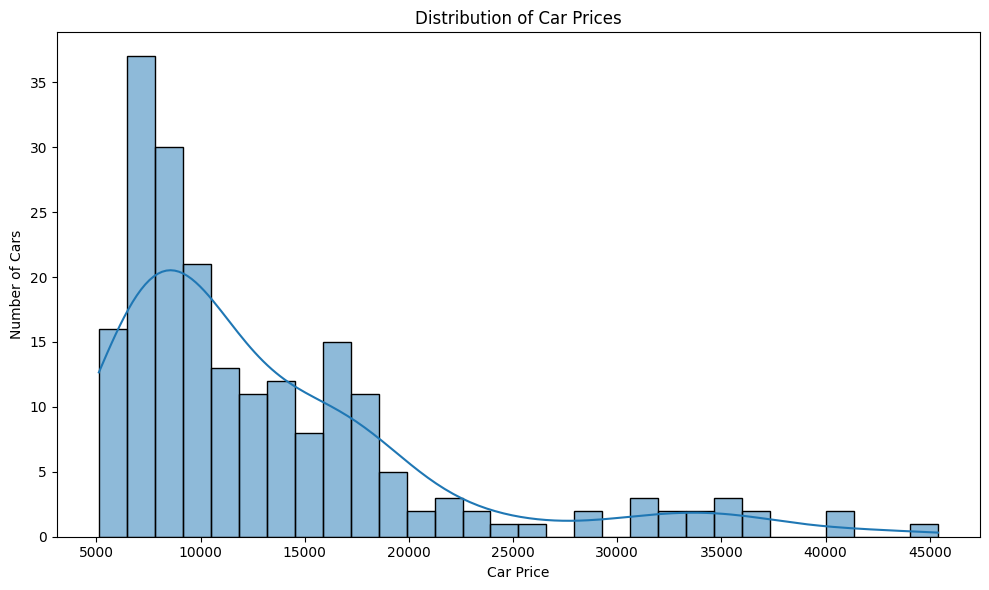

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(df["price"], bins=30, kde=True)
plt.title("Distribution of Car Prices")
plt.xlabel("Car Price")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()

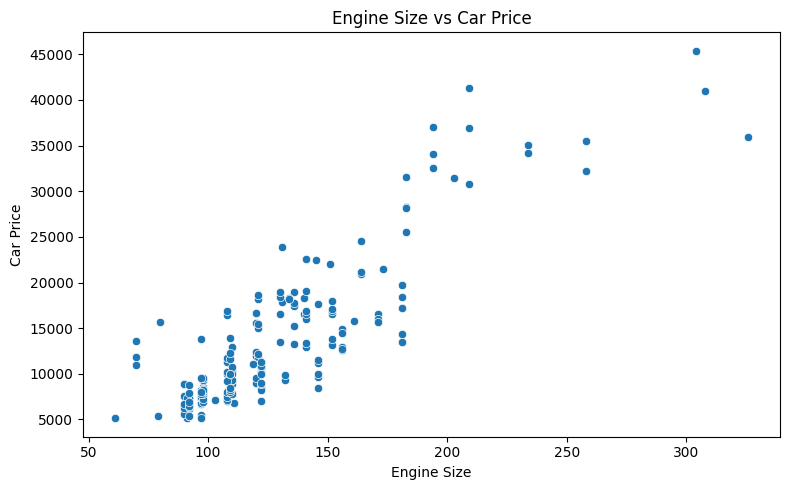

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="enginesize", y="price")
plt.title("Engine Size vs Car Price")
plt.xlabel("Engine Size")
plt.ylabel("Car Price")
plt.tight_layout()
plt.show()

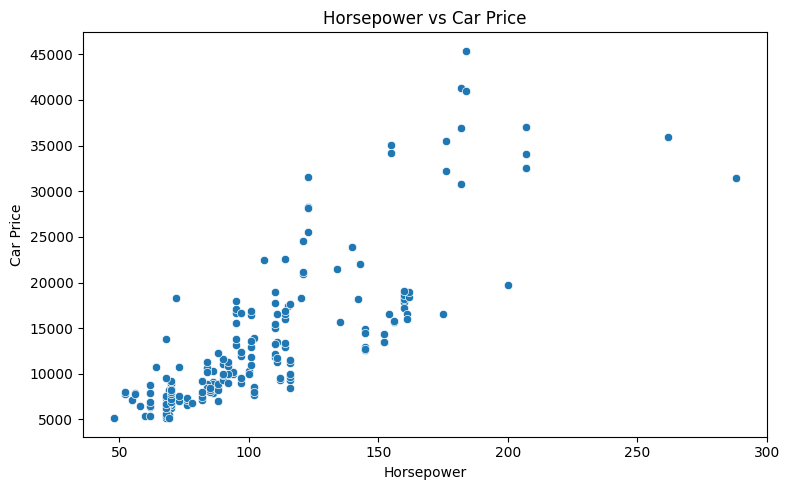

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="horsepower", y="price")
plt.title("Horsepower vs Car Price")
plt.xlabel("Horsepower")
plt.ylabel("Car Price")
plt.tight_layout()
plt.show()

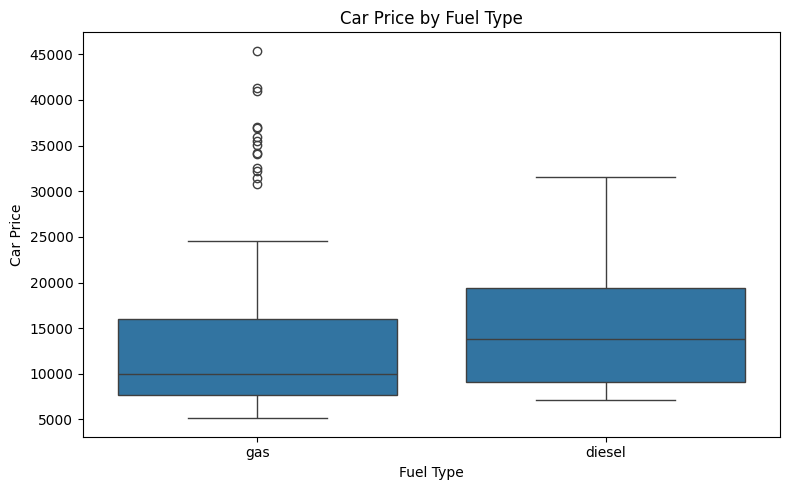

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="fueltype", y="price")

plt.title("Car Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Car Price")
plt.tight_layout()
plt.show()

In [ ]:
print("Average Price by Fuel Type:")
display(
    df.groupby("fueltype")["price"]
    .agg(["mean", "median", "count"])
    .round(2))


Average Price by Fuel Type:


,mean,median,count
fueltype,,,
diesel,15838.15,13852.5,20
gas,12999.80,9989.0,185


In [ ]:
X = df.drop(columns=["price", "CarName"])
y = df["price"]

X = pd.get_dummies(X, drop_first=True)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
display(X.head())

Feature matrix shape: (205, 44)
Target shape: (205,)


,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,...,cylindernumber_three,cylindernumber_twelve,cylindernumber_two,fuelsystem_2bbl,fuelsystem_4bbl,fuelsystem_idi,fuelsystem_mfi,fuelsystem_mpfi,fuelsystem_spdi,fuelsystem_spfi
0,1,3,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,...,False,False,False,False,False,False,False,True,False,False
1,2,3,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,...,False,False,False,False,False,False,False,True,False,False
2,3,1,94.5,171.2,65.5,52.4,2823,152,2.68,3.47,...,False,False,False,False,False,False,False,True,False,False
3,4,2,99.8,176.6,66.2,54.3,2337,109,3.19,3.40,...,False,False,False,False,False,False,False,True,False,False
4,5,2,99.4,176.6,66.4,54.3,2824,136,3.19,3.40,...,False,False,False,False,False,False,False,True,False,False


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)


Training features: (164, 44)
Testing features: (41, 44)
Training targets: (164,)
Testing targets: (41,)


In [ ]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

for name, predictions in [
    ("Linear Regression", y_pred_lr),
    ("Random Forest", y_pred_rf)
]:
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)
display(results_df.round(2))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1990.61,2802.24,0.90
1,Random Forest,1279.30,1824.30,0.96


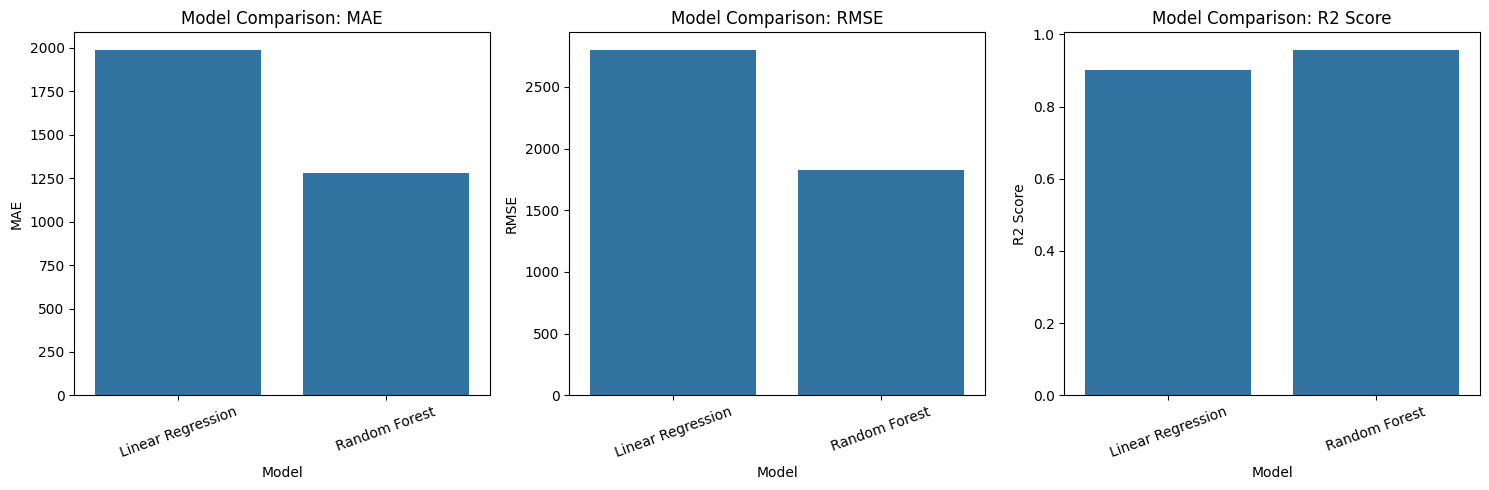

In [ ]:
metrics = ["MAE", "RMSE", "R2 Score"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, metric in zip(axes, metrics):
    sns.barplot(data=results_df, x="Model", y=metric, ax=ax)
    ax.set_title(f"Model Comparison: {metric}")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

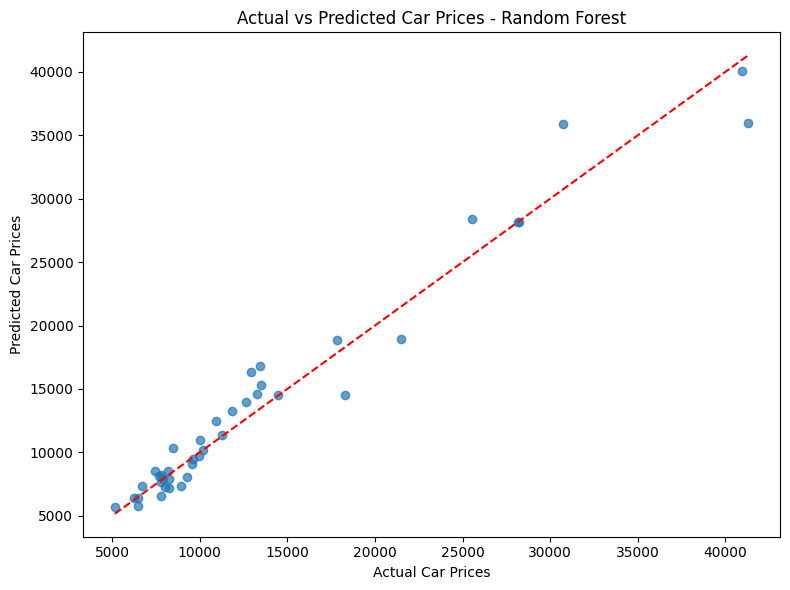

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_rf, alpha=0.7)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Car Prices")
plt.ylabel("Predicted Car Prices")
plt.title("Actual vs Predicted Car Prices - Random Forest")
plt.tight_layout()
plt.show()

In [ ]:
sample_cars = X_test.iloc[:5]

sample_predictions = rf_model.predict(sample_cars)

prediction_results = pd.DataFrame({
    "Actual Price": y_test.iloc[:5].values,
    "Predicted Price": sample_predictions
})

prediction_results["Difference"] = (
    prediction_results["Actual Price"]
    - prediction_results["Predicted Price"]
)

display(prediction_results.round(2))

,Actual Price,Predicted Price,Difference
0,30760.00,35875.83,-5115.83
1,17859.17,18835.03,-975.86
2,9549.00,9046.30,502.70
3,11850.00,13230.24,-1380.24
4,28248.00,28143.11,104.89


## Conclusion

In this project, a car price prediction system was developed using machine learning. The dataset was explored and cleaned, and exploratory data analysis was performed to understand the relationship between car features and selling prices.

Two regression models, Linear Regression and Random Forest Regressor, were trained and evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score. Actual and predicted prices were also compared to assess model performance.

The comparison of evaluation metrics helps identify the more suitable model for predicting car prices. This project demonstrates how machine learning can support price estimation based on a vehicle's characteristics.